# CSC173 — Member 2: TF-IDF + Logistic Regression Baseline
Trains the baseline on the shared training split, evaluates it on the held-out test split, and saves predictions + metrics so they can be compared with DistilBERT (Member 3).

**Inputs (from Member 1):** `headlines_train.csv`, `headlines_test.csv`, `headline_validation.csv`

**Outputs:** `tfidf_lr_predictions.csv`, `tfidf_lr_metrics.json`, `tfidf_lr_confusion_matrix.png`, `tfidf_lr.joblib` (for the demo notebook)

**Label convention (same as the cleaned data):** 0 = non-clickbait, 1 = clickbait. Clickbait is the positive class for precision, recall and F1.

## 0. Setup

In [1]:
import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

pd.set_option("display.max_colwidth", 120)

TRAIN_PATH = "headlines_train.csv"   # shared training split from Member 1
TEST_PATH  = "headlines_test.csv"    # shared held-out test split from Member 1
OUT_DIR    = "member2_results"       # every output file goes in this folder
SEED       = 42                      # fixed so results are reproducible
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the shared train/test split
If the files aren't in Colab yet, the cell will ask you to upload them. Do not make your own split,
 both models must use Member 1's exact files so the comparison is fair.

In [2]:
missing = [p for p in (TRAIN_PATH, TEST_PATH) if not os.path.exists(p)]
if missing:
    from google.colab import files
    print("Please upload:", missing)
    files.upload()

# utf-8-sig because Member 1 saved the files with a BOM (so Excel shows text correctly)
train_df = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig")
test_df  = pd.read_csv(TEST_PATH,  encoding="utf-8-sig")
print("Train:", train_df.shape, "| Test:", test_df.shape)
train_df.head()

Please upload: ['headlines_train.csv', 'headlines_test.csv']


Saving headlines_test.csv to headlines_test.csv
Saving headlines_train.csv to headlines_train.csv
Train: (32166, 2) | Test: (10053, 2)


,headline,label
0,France votes no in EU referendum,0
1,A gorgeous 1890 postcard tour of the Alpine land of Tyrol,0
2,A Bumblebee Gets New Protection on Obama’s Way Out,0
3,Judge issues final order upholding Alabama same-sex marriage,0
4,Ryanair executives pay frozen over increased fuel prices,0


## 2. Sanity checks
Confirms these are the right files: expected shapes are **(40208, 2)** for train and **(10053, 2)** for test, with about 60.8% non-clickbait / 39.2% clickbait in both.

In [3]:
for name, d in (("train", train_df), ("test", test_df)):
    assert list(d.columns[:2]) == ["headline", "label"], f"{name}: unexpected columns {list(d.columns)}"
    assert d["headline"].notna().all(), f"{name}: missing headlines"
    assert d["label"].isin([0, 1]).all(), f"{name}: labels must be 0/1"

print("Train label share:\n", train_df["label"].value_counts(normalize=True).round(3))
print("\nTest label share:\n", test_df["label"].value_counts(normalize=True).round(3))

# No headline may appear in both splits (that would leak test data into training)
assert not set(train_df["headline"]) & set(test_df["headline"]), "Leakage: headline in both splits!"
print("\nNo headline overlap between train and test ✔")

# Separate the text (X) from the answer (y)
X_train, y_train = train_df["headline"].astype(str), train_df["label"].astype(int)
X_test,  y_test  = test_df["headline"].astype(str),  test_df["label"].astype(int)

Train label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64

Test label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64

No headline overlap between train and test ✔


## 3. Train the baseline (TF-IDF + Logistic Regression)
- **TF-IDF** turns each headline into numbers based on which words/word-pairs it contains and how distinctive they are.
- **Logistic Regression** learns which of those features point to clickbait.

The vectorizer sits **inside** the pipeline, so the vocabulary is learned from the training data only. Settings are fixed and not tuned on the test set.

In [4]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),     # single words and two-word phrases
        min_df=2,               # ignore words seen in fewer than 2 headlines
        sublinear_tf=True)),    # dampen very frequent words
    ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
])

model.fit(X_train, y_train)     # learns from the TRAINING data only
print("Training done. Vocabulary size:", len(model.named_steps["tfidf"].vocabulary_))

Training done. Vocabulary size: 44165


## 4. Validate on the validation set
Before touching the test set, the trained model is checked on `headline_validation.csv`. The model is not trained or tuned on these headlines, so this is only a quick check that it works on unseen data. The final results reported for the comparison still come from the test set (Section 5).

In [5]:
VAL_PATH = "headline_validation.csv"   # shared validation split (change if the file name differs)

if not os.path.exists(VAL_PATH):
    from google.colab import files
    print("Please upload:", VAL_PATH)
    files.upload()

val_df = pd.read_csv(VAL_PATH, encoding="utf-8-sig")
print("Validation:", val_df.shape)

# Same checks as the train and test files
assert list(val_df.columns[:2]) == ["headline", "label"], f"validation: unexpected columns {list(val_df.columns)}"
assert val_df["headline"].notna().all(), "validation: missing headlines"
assert val_df["label"].isin([0, 1]).all(), "validation: labels must be 0/1"
print("Validation label share:\n", val_df["label"].value_counts(normalize=True).round(3))

# No validation headline may appear in the train or test split
assert not set(val_df["headline"]) & set(train_df["headline"]), "Leakage: validation headline in train!"
assert not set(val_df["headline"]) & set(test_df["headline"]), "Leakage: validation headline in test!"
print("\nNo headline overlap between validation and train/test ✔")

X_val, y_val = val_df["headline"].astype(str), val_df["label"].astype(int)

val_pred = model.predict(X_val)
val_cm = confusion_matrix(y_val, val_pred, labels=[0, 1])

print(f"\nValidation accuracy            : {accuracy_score(y_val, val_pred):.4f}")
print(f"Validation clickbait precision : {precision_score(y_val, val_pred, pos_label=1):.4f}")
print(f"Validation clickbait recall    : {recall_score(y_val, val_pred, pos_label=1):.4f}")
print(f"Validation clickbait F1-score  : {f1_score(y_val, val_pred, pos_label=1):.4f}")

print("\nValidation confusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(val_cm, index=["true non-clickbait", "true clickbait"],
                   columns=["pred non-clickbait", "pred clickbait"]))

Please upload: headline_validation.csv


Saving headline_validation.csv to headline_validation.csv
Validation: (8042, 2)
Validation label share:
 label
0    0.608
1    0.392
Name: proportion, dtype: float64

No headline overlap between validation and train/test ✔

Validation accuracy            : 0.8963
Validation clickbait precision : 0.8989
Validation clickbait recall    : 0.8287
Validation clickbait F1-score  : 0.8624

Validation confusion matrix (rows = true class, columns = predicted class):
                    pred non-clickbait  pred clickbait
true non-clickbait                4595             294
true clickbait                     540            2613


## 5. Evaluate on the held-out test set
The model has never seen these headlines, so this shows how well it works on new data. Predictions use the default 0.5 threshold.

In [6]:
y_pred = model.predict(X_test)                  # predicted class (0 or 1)
y_prob = model.predict_proba(X_test)[:, 1]      # P(clickbait), later used for the 0–100% score

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])   # [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()

metrics = {
    "model": "TF-IDF + Logistic Regression",
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "threshold": 0.5,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "clickbait_precision": float(precision_score(y_test, y_pred, pos_label=1)),
    "clickbait_recall": float(recall_score(y_test, y_pred, pos_label=1)),
    "clickbait_f1": float(f1_score(y_test, y_pred, pos_label=1)),
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_labels": ["non_clickbait(0)", "clickbait(1)"],
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}

print(f"Accuracy            : {metrics['accuracy']:.4f}")
print(f"Clickbait precision : {metrics['clickbait_precision']:.4f}")
print(f"Clickbait recall    : {metrics['clickbait_recall']:.4f}")
print(f"Clickbait F1-score  : {metrics['clickbait_f1']:.4f}")

print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(cm, index=["true non-clickbait", "true clickbait"],
                   columns=["pred non-clickbait", "pred clickbait"]))

print("\nFull report:")
print(classification_report(y_test, y_pred, target_names=["non-clickbait", "clickbait"], digits=4))

Accuracy            : 0.8923
Clickbait precision : 0.8961
Clickbait recall    : 0.8204
Clickbait F1-score  : 0.8565

Confusion matrix (rows = true class, columns = predicted class):
                    pred non-clickbait  pred clickbait
true non-clickbait                5737             375
true clickbait                     708            3233

Full report:
               precision    recall  f1-score   support

non-clickbait     0.8901    0.9386    0.9138      6112
    clickbait     0.8961    0.8204    0.8565      3941

     accuracy                         0.8923     10053
    macro avg     0.8931    0.8795    0.8851     10053
 weighted avg     0.8925    0.8923    0.8913     10053



### 6. Confusion matrix plot (for the report)

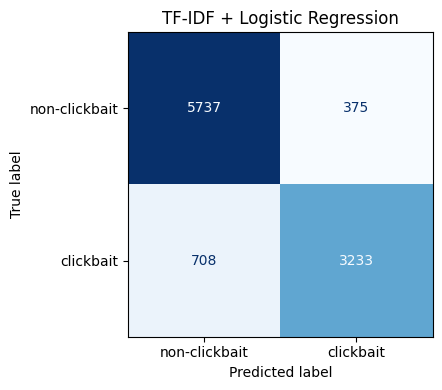

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["non-clickbait", "clickbait"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tfidf_lr_confusion_matrix.png", dpi=150)
plt.show()

## 7. Save predictions, metrics and the model
- Predictions keep the **same row order as `headlines_test.csv`**, so they can be lined up with DistilBERT's.
- Metric names (`accuracy`, `clickbait_precision`, `clickbait_recall`, `clickbait_f1`, `confusion_matrix`) should be reused by Member 3 so the results match.
- `tfidf_lr.joblib` is the full pipeline (vectorizer + model) that Member 1's demo notebook loads.

In [8]:
preds = pd.DataFrame({
    "row_id": np.arange(len(test_df)),   # position in headlines_test.csv
    "headline": test_df["headline"].values,
    "y_true": y_test.values,
    "y_pred": y_pred,
    "prob_clickbait": y_prob,            # x100 gives the proposed 0–100% score
})
preds.to_csv(f"{OUT_DIR}/tfidf_lr_predictions.csv", index=False, encoding="utf-8-sig")

with open(f"{OUT_DIR}/tfidf_lr_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

joblib.dump(model, f"{OUT_DIR}/tfidf_lr.joblib")

print("Saved to", OUT_DIR + "/:", sorted(os.listdir(OUT_DIR)))
preds.head()

Saved to member2_results/: ['tfidf_lr.joblib', 'tfidf_lr_confusion_matrix.png', 'tfidf_lr_metrics.json', 'tfidf_lr_predictions.csv']


,row_id,headline,y_true,y_pred,prob_clickbait
0,0,"This Color Test Will Determine If You're Sexy, Hot, Or Cute",1,1,0.984815
1,1,Well-wishers raise thousands for teenage asylum seeker attacked in Croydon,0,0,0.059859
2,2,Cardboard And Caviar: Documenting Homelessness In London's Bourgeois Boroughs,1,0,0.086724
3,3,Here's a Throwback Picture of a Young Draymond Green with a Huge Afro,0,0,0.359746
4,4,26 Questions Cats Just Need To Answer,1,1,0.941205


## 8. Download files to share with Members 1 & 3
- `tfidf_lr_predictions.csv` and `tfidf_lr_metrics.json` → Member 3 (comparison)
- `tfidf_lr.joblib` → Member 1 (demo notebook)
- `tfidf_lr_confusion_matrix.png` → for the report

In [9]:
try:
    from google.colab import files
    for f in sorted(os.listdir(OUT_DIR)):
        files.download(os.path.join(OUT_DIR, f))
except ImportError:
    print("Not in Colab — files are in the folder:", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>